# Return simulations: GBM and historical bootstrap

Estimate model parameters using prices strictly before February 1, 2024,
then simulate 252 future trading steps using 10,000 paths.

Both models start at the purchase-date close of approximately $16.33.

In [1]:
import numpy as np, pandas as pd, json, sys, yfinance as yf, plotly.express as px, scipy.stats as sc, requests
start, end = "2023-05-01", "2025-05-02"
purchase_date = "2024-02-01"
SEED = 67
n = 252
rng = np.random.default_rng(SEED)

In [2]:
%pip install kaleido
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+png"


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [3]:
PLTR = pd.read_csv("../data/pltr_prices.csv", index_col=0, parse_dates=True).sort_index()
pre_purchase = PLTR[PLTR.index < purchase_date]

training_prices = pre_purchase["Close"]
training_percentages = pre_purchase["Close"].pct_change()


## Estimating annual drift and volatility ~ GBM

Simple statistics tell us:

- V(X/n) = V(X) / n = σ²/n
- std(X/n) = σ / √n
- √n * sampleSTD = σ

We have 252 trading days in the US-stock market:
    σ = √252 * sampleSTD

For GBM:
- μ ~ Expected drift, m ~ Mean daily log return
- m = μ - 0.5 * σ²


In [4]:
log_returns = np.log(1 + training_percentages).dropna()
m = log_returns.mean() * n
sigma = log_returns.std() * np.sqrt(n)
drift = m + 0.5 * sigma**2

print(f"Annual drift: {drift:.2%}\nAnnual volatility: {sigma:.2%}")

Annual drift: 119.02%
Annual volatility: 66.54%


## GBM: fixed volatility and random shocks ~ 1 year


Daily log-return increments have mean mΔt and standard deviation σ√Δt.

We will use timesteps `Δ = 1 / trading days = 1 / 252`, and `10_000 simulations`


In [5]:
dt, n_sim = 1 / n, 10_000
starting_price = PLTR.loc[purchase_date]["Close"]

### Simulated price paths
`Simulation`

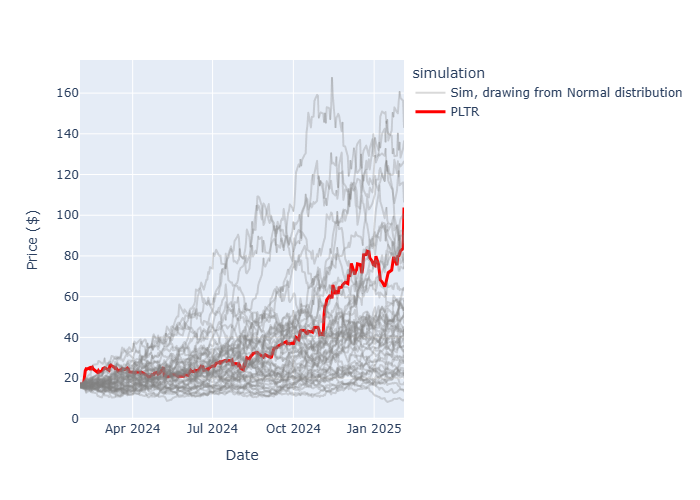

In [6]:
steps_normal = rng.normal(m * dt, sigma * np.sqrt(dt), size=(n, n_sim))
simulations_normal = starting_price * np.exp(np.vstack([np.zeros(n_sim), steps_normal.cumsum(axis=0)]))
dated_simulations_normal = pd.DataFrame(simulations_normal, index=PLTR.loc["2024-02-01":].index[:len(simulations_normal)])

fig = px.line(dated_simulations_normal.iloc[:, :50], labels={"variable":"simulation", "value":"Price ($)", "index":f"Days since: {purchase_date}"})
fig.update_traces(line_color="grey", opacity=0.3, name="Sim, drawing from Normal distribution", showlegend=False)

actual = PLTR.loc[dated_simulations_normal.index, "Close"]

fig.add_scatter(x=actual.index, y=actual, line=dict(color="red", width=3), mode="lines", name="PLTR")
fig.data[0].showlegend = True ; fig.show()

### Price distribution
The histogram’s mean and standard deviation describe terminal prices in dollars.

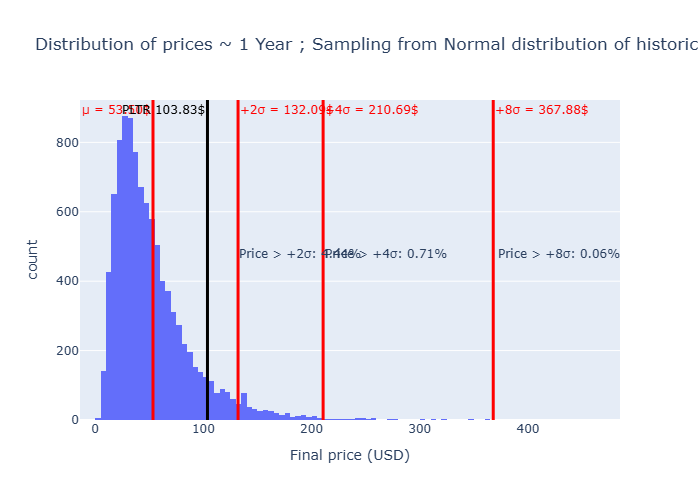

P(Price > PLTR): 9.10%


In [7]:
dis = simulations_normal[-1, :]
fig = px.histogram(x=dis, nbins=100, histfunc="count", labels={"x": "Final price (USD)"}, title="Distribution of prices ~ 1 Year ; Sampling from Normal distribution of historic returns")

μ = simulations_normal[-1, :].mean()
σ = simulations_normal[-1, :].std()

fig.add_vline(
    x=μ, line_color="red", line_width=3,
    annotation_text=f"μ = {μ:.2f}$",
    annotation_position=f"top left",
    annotation_font_color="red")
fig.add_vline(
    x=actual.iloc[-1], line_color="black", line_width=3,
    annotation_text=f"PLTR {actual.iloc[-1]:.2f}$",
    annotation_position=f"top left",
    annotation_font_color="black")

for a in (1, 2, 4, 8):
    for s in (+σ, ):
        if a < 2: continue
        fig.add_vline(
            x=μ + a*s, line_color="red", line_width=3,
            annotation_text=f"{'+' if s > 0 else '-'}{a}σ = {(μ + a*s):.2f}$",
            annotation_position=f"top {"right" if s > 0 else "left"}",
            annotation_font_color="red")
        fig.add_annotation(
            x=0.13 + a*0.08, y=0.55, xref="paper", yref="paper",
            text=f"Price > +{a}σ: {(simulations_normal[-1, :] > μ + a*σ).mean() * 100:.2f}%",
            showarrow=False, xanchor="left", yanchor="top")
fig.show()
print(f"P(Price > PLTR): {(simulations_normal[-1, :] > actual.iloc[-1]).mean() * 100:.2f}%")

## Historical bootstrap

~ Drawing from historical returns

Sample observed pre-purchase daily log returns independently with replacement.
A historical return can therefore appear multiple times in a simulated path.

`Simulation`

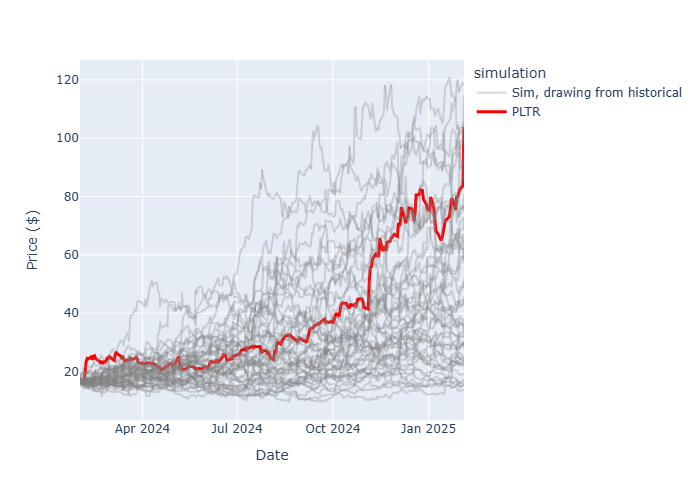

In [8]:
steps_historic = rng.choice(log_returns.to_numpy(), size=(n, n_sim), replace=True)
simulations_historic = starting_price * np.exp(np.vstack([np.zeros(n_sim), steps_historic.cumsum(axis=0)]))

dated_simulations_historic = pd.DataFrame(simulations_historic, index=PLTR.loc["2024-02-01":].index[:len(simulations_historic)])
fig = px.line(dated_simulations_historic.iloc[:, :50], labels={"variable":"simulation", "value":"Price ($)", "index":f"Days since: {purchase_date}"})
fig.update_traces(line_color="grey", opacity=0.3, name="Sim, drawing from historical", showlegend=False)

fig.add_scatter(x=actual.index, y=actual, line=dict(color="red", width=3), mode="lines", name="PLTR")
fig.data[0].showlegend = True ; fig.show()

### Price Distribution

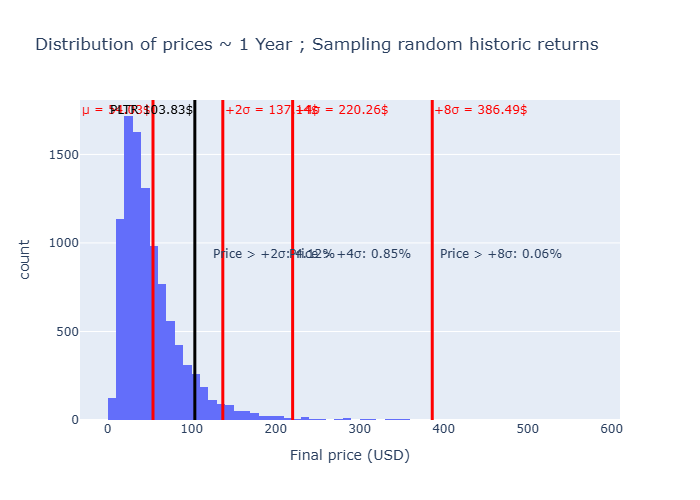

P(Price > PLTR): 9.56%


In [9]:
dis = simulations_historic[-1, :]
fig = px.histogram(x=dis, nbins=100, histfunc="count", labels={"x": "Final price (USD)"}, title="Distribution of prices ~ 1 Year ; Sampling random historic returns")

μ = simulations_historic[-1, :].mean()
σ = simulations_historic[-1, :].std()

fig.add_vline(
    x=μ, line_color="red", line_width=3,
    annotation_text=f"μ = {μ:.2f}$",
    annotation_position=f"top left",
    annotation_font_color="red")

fig.add_vline(
    x=actual.iloc[-1], line_color="black", line_width=3,
    annotation_text=f"PLTR {actual.iloc[-1]:.2f}$",
    annotation_position=f"top left",
    annotation_font_color="black")

for a in (1, 2, 4, 8):
    for s in (+σ, ):
        if a < 2: continue
        fig.add_vline(
            x=μ + a*s, line_color="red", line_width=3,
            annotation_text=f"{'+' if s > 0 else '-'}{a}σ" + (f" = {(μ + a*s):.2f}$" if a > 1 else ""),
            annotation_position=f"top {"right" if s > 0 else "left"}",
            annotation_font_color="red")
        fig.add_annotation(
            x=0.103 + a*0.07, y=0.55, xref="paper", yref="paper",
            text=f"Price > +{a}σ: {(simulations_historic[-1, :] > μ + a*σ).mean() * 100:.2f}%",
            showarrow=False, xanchor="left", yanchor="top")

fig.show()
print(f"P(Price > PLTR): {(simulations_historic[-1, :] > actual.iloc[-1]).mean() * 100:.2f}%")

## Conclusions

GBM and the historical bootstrap produced similar one-year price distributions, with mean final prices around $54. Both models use the same historical sample, and aggregating 252 independent daily log returns explain the similar results, due to the Central Limit Theorem of sums of iid rv's (CLT). 

The real ending price exceeded 90.90% of GBM outcomes and 90.44% of
bootstrap outcomes.